First we load the necessary libraries

In [1]:
import pypsa
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## TASK 1 : Network Optimization and Generator Dispatch Analysis. 

We take the meshed AC-DC network example from PyPSA and modify it to keep the Norwich converter capacity fixed.

In [2]:
# Loading the AC-DC meshed network
m_net = pypsa.examples.ac_dc_meshed()

# Setting the p_nom_extendable attribute of the link "Norwich Converter" to False
m_net.links.loc["Norwich Converter", "p_nom_extendable"] = False

print(m_net)

/home/sammy/sfu-pypsa-assignment/.venv/lib/python3.12/site-packages/pypsa/network/io.py:2079: FutureWarning: pandas infers the `str` dtype for string data since its version 3.0. PyPSA still converts it back to numpy object dtype on import, but will keep it from PyPSA 2.0 on. Set `pypsa.options.api.legacy_string_dtype` explicitly to suppress this warning.
  new_static = _coerce_string_dtypes(new_static)
INFO:pypsa.network.io:Imported network 'AC-DC-Meshed' has buses, carriers, generators, global_constraints, lines, links, loads


PyPSA Network 'AC-DC-Meshed'


Lets inspect the generators in the network to see their attributes, including whether they are extendable or not.

In [3]:
generator_info = m_net.generators[
    ["bus", "carrier", "p_nom", "p_nom_extendable",
     "p_nom_min", "capital_cost", "marginal_cost"]
]

display(generator_info)

,bus,carrier,p_nom,p_nom_extendable,p_nom_min,capital_cost,marginal_cost
name,,,,,,,
Manchester Wind,Manchester,wind,80.0,True,100.0,2793.651603,0.110000
Manchester Gas,Manchester,gas,50000.0,True,0.0,196.615168,4.532368
Norway Wind,Norway,wind,100.0,True,100.0,2184.374796,0.090000
Norway Gas,Norway,gas,20000.0,True,0.0,158.251250,5.892845
Frankfurt Wind,Frankfurt,wind,110.0,True,100.0,2129.456122,0.100000
Frankfurt Gas,Frankfurt,gas,80000.0,True,0.0,102.676953,4.086322


All Gas based generators have very large nominal capacities than the renewables. We can see that they also have very small capital cost and a very high marginal cost. Frankfurt has both the lowest capital cost and the lowest marginal generation cost among them.  Economicaly speaking, they are primarily not meant to be used in the optimal dispatch of the network, but rather as a backup for when renewable generation is not sufficient to meet demand. We will assess it further after running the dispatch optimization.

We examine electricity demand in the network.

In [4]:
# Print the load information in the network
display(m_net.loads)

# Print the active power demand (p_set) of the loads in the network
display(m_net.loads_t.p_set)

,bus,carrier,type,p_set,q_set,sign,active
name,,,,,,,
London,London,load,,0.0,0.0,-1.0,True
Frankfurt,Frankfurt,load,,0.0,0.0,-1.0,True
Norway,Norway,load,,0.0,0.0,-1.0,True
Norwich,Norwich,load,,0.0,0.0,-1.0,True
Bremen,Bremen,load,,0.0,0.0,-1.0,True
Manchester,Manchester,load,,0.0,0.0,-1.0,True


name,London,Norwich,Frankfurt,Bremen,Norway,Manchester
snapshot,,,,,,
2015-01-01 00:00:00,35.796244,415.462564,398.047847,640.086378,820.035836,857.551440
2015-01-01 01:00:00,976.824561,262.606146,432.436106,703.554334,854.834047,750.599624
2015-01-01 02:00:00,250.587312,418.476353,379.803928,440.836130,42.550744,156.564876
2015-01-01 03:00:00,130.753145,552.959539,868.361764,612.576306,647.548233,527.870822
2015-01-01 04:00:00,151.100169,218.159858,548.770755,803.436781,884.073873,83.897759
2015-01-01 05:00:00,931.857052,791.976266,828.665243,605.400687,509.062449,676.623319
2015-01-01 06:00:00,289.848287,531.870681,449.290752,641.090590,595.607965,731.137100
2015-01-01 07:00:00,864.343322,23.513467,699.163766,408.008541,291.642450,553.344889
2015-01-01 08:00:00,689.577264,970.059068,915.866780,912.247776,2.153493,298.338082


We run the optimization using the "highs" solver.

In [5]:
status, condition = m_net.optimize(solver_name="highs")

/tmp/ipykernel_48352/337597941.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  status, condition = m_net.optimize(solver_name="highs")
Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.39s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -3.47e+06
Solver: highs
Runtime: 0.02s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-p-lowe

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-gx3vruzs has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [1e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [9e-01, 1e+03]
Presolving model
371 rows, 186 cols, 890 nonzeros 0s
284 rows, 99 cols, 932 nonzeros 0s
Dependent equations search running on 23 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
284 rows, 99 cols, 932 nonzeros 0s
Presolve reductions: rows 284(-183); columns 99(-88); nonzeros 932(-54) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1204315698e+07 Pr: 110(102101); Du: 0(1.47519e-11) 0.0s
        119    -3.4740941308e+06 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the s

In [6]:
# We verify that the optimization was successful

print("Status:", status)
print("Termination condition:", condition)

Status: ok
Termination condition: optimal


Lets examine the optimized generator capacity

In [7]:
optimized_capacity = (
    m_net.generators[["bus", "p_nom", "p_nom_opt"]]
    .sort_values("p_nom_opt", ascending=False)
)

display(optimized_capacity.round(2))

,bus,p_nom,p_nom_opt
name,,,
Manchester Wind,Manchester,80.0,4090.81
Frankfurt Wind,Frankfurt,110.0,1667.72
Norway Wind,Norway,100.0,1533.60
Frankfurt Gas,Frankfurt,80000.0,982.03
Manchester Gas,Manchester,50000.0,0.00
Norway Gas,Norway,20000.0,0.00


How much electricity is generated by each generator at 5:00 AM on January 1, 2015?

In [8]:
snapshot = pd.Timestamp("2015-01-01 05:00:00")

dispatch_0500 = m_net.generators_t.p.loc[snapshot]

display(dispatch_0500.sort_values(ascending=False).round(2))

name
Manchester Wind    2469.21
Frankfurt Gas       982.03
Frankfurt Wind      877.48
Norway Wind          14.86
Manchester Gas       -0.00
Norway Gas           -0.00
Name: 2015-01-01 05:00:00, dtype: float64

From the above we could see that the optimized model dispatches all the renewable wind energy sources from Macheste, Frankfurt and Norway with the Frankfurt gas being the only fossil plant that is dispatched. The rest of the fossil plants are not dispatched at all. This is because the renewable energy sources have a lower marginal cost than the fossil plants, and therefore they are prioritized in the dispatch. 
What is not clear for now is why the Frankfurt Gas is the only fossil generator dispatched at its full optimized capacity ahead of Norway Wind. We need to assess whether wind availability and locational marginal prices contributed to this dispatch pattern.

In [9]:
snapshot = pd.Timestamp("2015-01-01 05:00:00")

# Wind availability and actual generation
wind_generators = m_net.generators.index[
    m_net.generators.carrier == "wind"
]

wind_analysis = pd.DataFrame({
    "Installed capacity (MW)": m_net.generators.loc[
        wind_generators, "p_nom_opt"
    ],
    "Availability factor": m_net.generators_t.p_max_pu.loc[
        snapshot, wind_generators
    ],
    "Actual dispatch (MW)": m_net.generators_t.p.loc[
        snapshot, wind_generators
    ]
})

wind_analysis["Available generation (MW)"] = (
    wind_analysis["Installed capacity (MW)"]
    * wind_analysis["Availability factor"]
)

display(wind_analysis.round(2))

,Installed capacity (MW),Availability factor,Actual dispatch (MW),Available generation (MW)
name,,,,
Manchester Wind,4090.81,0.60,2469.21,2469.21
Norway Wind,1533.60,0.01,14.86,14.86
Frankfurt Wind,1667.72,0.53,877.48,877.48


It is clear that the actual dispatch of the wind generators is limited by their availability factor and that availability varies substantially across locations. Manchester wind and Frankfurt Wind operate at approximately 60% and 53% of their installed capacities, respectively, whereas Norway Wind has an availability factor of only about 1% at 5 oclock. All of three wind generators dispatch their full available output. This means that no wind energy is curtailed at this hour.

In [10]:
# Locational marginal prices of electricity prices at 05:00
prices_0500 = m_net.buses_t.marginal_price.loc[snapshot]

display(prices_0500.round(2))

name
London        1593.66
Norwich       1593.66
Norwich DC    1593.66
Manchester    1593.66
Bremen        1593.66
Bremen DC     1593.66
Frankfurt     1593.46
Norway        1593.66
Norway DC     1593.66
Name: 2015-01-01 05:00:00, dtype: float64

The LMPs are nearly identical across the network, ranging from approximately €1,593.46/MWh in Frankfurt to €1,593.66/MWh in other locations. This dispatch is consistent with cost-minimizing generation under variable wind availability.

In [11]:
snapshot = pd.Timestamp("2015-01-01 05:00:00")

# Generator information
hourly_merit = m_net.generators[
    ["carrier", "marginal_cost", "p_nom_opt"]
].copy()

# Wind availability at the selected hour
hourly_merit["availability"] = 1.0

wind_units = hourly_merit.index[
    hourly_merit["carrier"] == "wind"
]

hourly_merit.loc[wind_units, "availability"] = (
    m_net.generators_t.p_max_pu.loc[snapshot, wind_units]
)

# Available capacity
hourly_merit["available_mw"] = (
    hourly_merit["p_nom_opt"] * hourly_merit["availability"]
)

# Sort generators by marginal cost
hourly_merit = hourly_merit.sort_values("marginal_cost")

# Starting position of each generator block
hourly_merit["start_mw"] = (
    hourly_merit["available_mw"].cumsum()
    - hourly_merit["available_mw"]
)

display(hourly_merit.round(2))

,carrier,marginal_cost,p_nom_opt,availability,available_mw,start_mw
name,,,,,,
Norway Wind,wind,0.09,1533.60,0.01,14.86,0.00
Frankfurt Wind,wind,0.10,1667.72,0.53,877.48,14.86
Manchester Wind,wind,0.11,4090.81,0.60,2469.21,892.34
Frankfurt Gas,gas,4.09,982.03,1.00,982.03,3361.55
Manchester Gas,gas,4.53,0.00,1.00,0.00,4343.59
Norway Gas,gas,5.89,0.00,1.00,0.00,4343.59


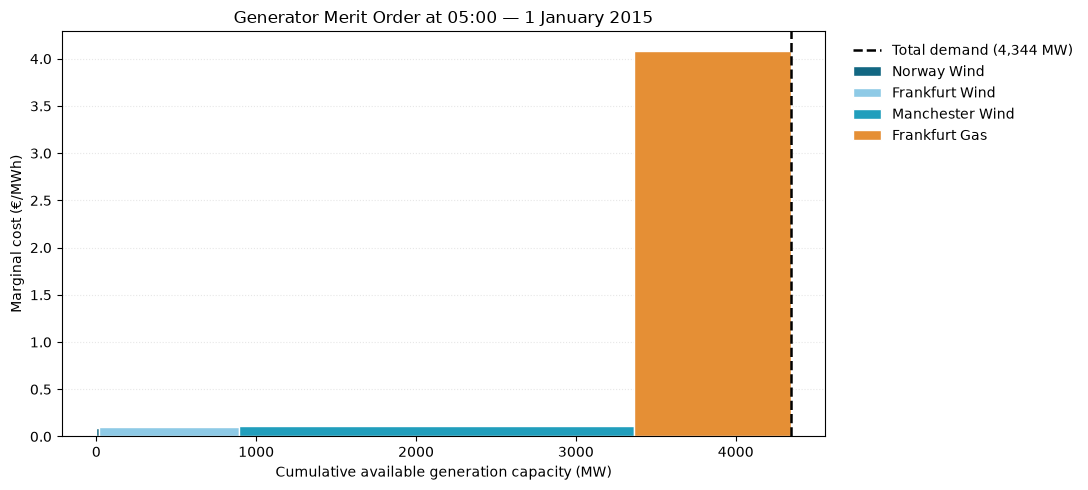

In [12]:
fig, ax = plt.subplots(figsize=(11, 5))

generator_colors = {
    "Norway Wind": "#126782",
    "Frankfurt Wind": "#8ECAE6",
    "Manchester Wind":"#219EBC",
    "Frankfurt Gas": "#E58F35",
    "Manchester Gas": "#F4B183",
    "Norway Gas": "#C65D3B"
}

for generator, row in hourly_merit.iterrows():
    if row["available_mw"] <= 0:
        continue

    ax.bar(
        row["start_mw"],
        row["marginal_cost"],
        width=row["available_mw"],
        align="edge",
        color=generator_colors[generator],
        edgecolor="white",
        linewidth=1,
        label=generator
    )

# Total electricity demand at 05:00
demand_0500 = m_net.loads_t.p_set.loc[snapshot].sum()

ax.axvline(
    demand_0500,
    color="black",
    linestyle="--",
    linewidth=1.8,
    label=f"Total demand ({demand_0500:,.0f} MW)"
)

ax.set_xlabel("Cumulative available generation capacity (MW)")
ax.set_ylabel("Marginal cost (€/MWh)")
ax.set_title("Generator Merit Order at 05:00 — 1 January 2015")

ax.legend(
    loc="upper left",
    bbox_to_anchor=(1.02, 1),
    frameon=False
)

ax.grid(axis="y", linestyle=":", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("../plots/merit_order_0500.png", dpi=300, bbox_inches="tight")
plt.show()

The figure above illustrates the merit order of generators at 05:00 on 1 January 2015. Wind generators are at the lower end of the supply curve due to their relatively lower marginal cost of production. However ther capacity are contrained by the weather. Total available wind generation is approximately 3,362 MW, compared with electricity demand of 4,344 MW. The resulting supply shortfall of approximately 982 MW is then met by Frankfurt Gas, which operates at its full optimized capacity. As discussed above, Frankfurt Gas has the lowest capital and marginal costs among the three gas generators. The optimization therefore selects Frankfurt Gas rather than Manchester Gas or Norway Gas.

## TASK 2: Electricity Generation, Wind Curtailment, and Energy Storage

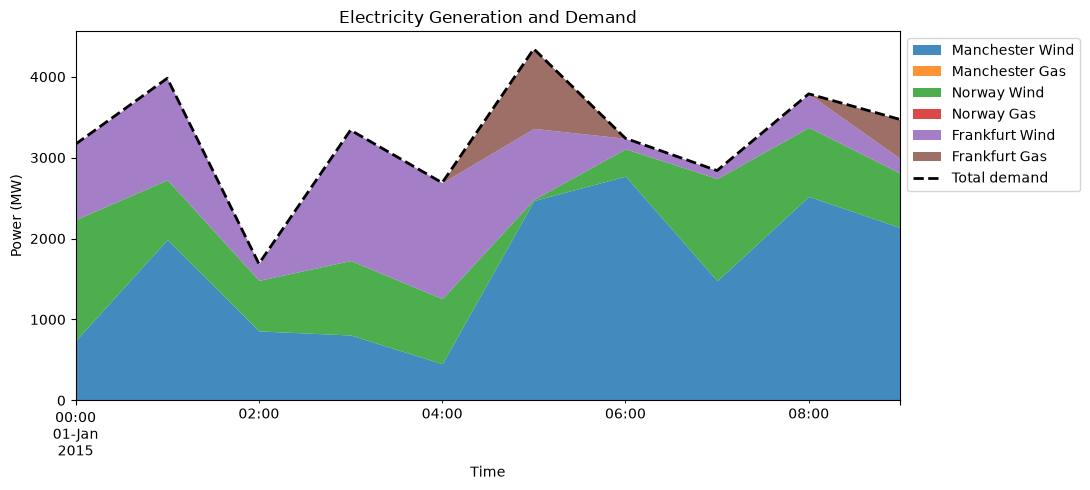

In [13]:
generator_dispatch = m_net.generators_t.p

total_demand = m_net.loads_t.p_set.sum(axis=1)

ax = generator_dispatch.plot.area(
    stacked=True,
    figsize=(11, 5),
    linewidth=0,
    alpha=0.85
)

total_demand.plot(
    ax=ax,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Total demand"
)

ax.set_title("Electricity Generation and Demand")
ax.set_xlabel("Time")
ax.set_ylabel("Power (MW)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()

plt.savefig("../plots/generation_and_demand.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
m_net.generators_t.p["Frankfurt Gas"].round(2)

snapshot
2015-01-01 00:00:00     -0.00
2015-01-01 01:00:00     -0.00
2015-01-01 02:00:00     -0.00
2015-01-01 03:00:00     -0.00
2015-01-01 04:00:00     -0.00
2015-01-01 05:00:00    982.03
2015-01-01 06:00:00     -0.00
2015-01-01 07:00:00     -0.00
2015-01-01 08:00:00     -0.00
2015-01-01 09:00:00    483.24
Name: Frankfurt Gas, dtype: float64

In [15]:
hours = pd.to_datetime([
    "2015-01-01 05:00:00",
    "2015-01-01 09:00:00"
])
# Identify wind generators
wind_units = m_net.generators.index[
    m_net.generators.carrier == "wind"
]

# Available wind generation at each snapshot
wind_available = (
    m_net.generators_t.p_max_pu[wind_units]
    * m_net.generators.loc[wind_units, "p_nom_opt"]
)

# Actual wind generation
wind_dispatch = m_net.generators_t.p[wind_units]
dispatch_comparison = pd.DataFrame({
    "Demand (MW)": m_net.loads_t.p_set.loc[hours].sum(axis=1),
    "Available wind (MW)": wind_available.loc[hours].sum(axis=1),
    "Wind dispatch (MW)": wind_dispatch.loc[hours].sum(axis=1),
    "Frankfurt Gas (MW)": m_net.generators_t.p.loc[hours, "Frankfurt Gas"]
})

dispatch_comparison["Wind shortfall (MW)"] = (
    dispatch_comparison["Demand (MW)"]
    - dispatch_comparison["Available wind (MW)"]
)

display(dispatch_comparison.round(2))

,Demand (MW),Available wind (MW),Wind dispatch (MW),Frankfurt Gas (MW),Wind shortfall (MW)
snapshot,,,,,
2015-01-01 05:00:00,4343.59,3361.55,3361.55,982.03,982.03
2015-01-01 09:00:00,3470.78,2987.54,2987.54,483.24,483.24


The table and pot show that wind supplies most electricity demand, while Frankfurt Gas operates mainly at 05:00 and 09:00, when available wind generation is insufficient to meet demand.

In [16]:
# Wind curtailment
wind_curtailment = (
    wind_available - wind_dispatch
).clip(lower=0)

# Total curtailed wind generation at each snapshot
total_curtailment = wind_curtailment.sum(axis=1)

curtailment_summary = pd.DataFrame({
    "Available wind (MW)": wind_available.sum(axis=1),
    "Dispatched wind (MW)": wind_dispatch.sum(axis=1),
    "Curtailment (MW)": total_curtailment
})

display(curtailment_summary.round(2))

,Available wind (MW),Dispatched wind (MW),Curtailment (MW)
snapshot,,,
2015-01-01 00:00:00,6231.54,3166.98,3064.56
2015-01-01 01:00:00,3980.85,3980.85,0.00
2015-01-01 02:00:00,1786.42,1688.82,97.60
2015-01-01 03:00:00,3586.07,3340.07,246.00
2015-01-01 04:00:00,4801.46,2689.44,2112.02
2015-01-01 05:00:00,3361.55,3361.55,0.00
2015-01-01 06:00:00,3245.27,3238.85,6.43
2015-01-01 07:00:00,2840.02,2840.02,0.00
2015-01-01 08:00:00,3810.42,3788.24,22.18


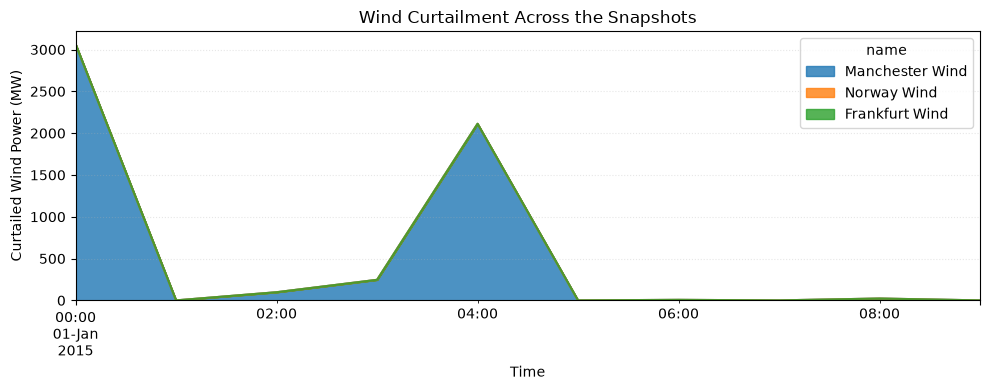

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))

wind_curtailment.plot.area(
    ax=ax,
    stacked=True,
    alpha=0.8
)

ax.set_title("Wind Curtailment Across the Snapshots")
ax.set_xlabel("Time")
ax.set_ylabel("Curtailed Wind Power (MW)")

ax.grid(axis="y", linestyle=":", alpha=0.3)

plt.tight_layout()
plt.savefig("../plots/wind_curtailment.png", dpi=300, bbox_inches="tight")
plt.show()

Wind curtailment occurs at several snapshots noticeably at 00:00 (3,064.56 MW) and 04:00 (2,112.02 MW), predominantly from Manchester Wind. Since some available renewable generation cannot be utilized under the models operating conditions, energy storage technologies such as batteries could absorb excess wind electricity and discharge during periods of insufficient wind supply, for example at hours of 05:00 and 09:00. Alternatively, electrolyzers could convert surplus electricity into hydrogen for storage and later use. These options could reduce reliance on gas generation and improve renewable energy utilization.

## TASK 3: Single-Node Optimization and Wind–Gas Investment Cost Sensitivity. At this stage, we modify the network, solve the new model, and then determine the capital-cost threhold at which Norway Wind replaces Frankfurt Gas.

We first create the single-node network

In [18]:
# Load the original example
single_net = pypsa.examples.ac_dc_meshed()

single_net.links.loc[
    "Norwich Converter", "p_nom_extendable"
] = False

# Connecting all generators and loads to Frankfurt
single_net.generators["bus"] = "Frankfurt"
single_net.loads["bus"] = "Frankfurt"

# Making sure Norway Wind is fully available at every snapshot
single_net.generators_t.p_max_pu.loc[:, "Norway Wind"] = 1.0

# setting these wind capacities to zero
single_net.generators.loc[
    ["Manchester Wind", "Frankfurt Wind"], "p_nom_min"
] = 0.0

INFO:pypsa.network.io:Imported network 'AC-DC-Meshed' has buses, carriers, generators, global_constraints, lines, links, loads


In [19]:
#Lets print nicely and review the generator and load buses, Norway Wind availability, and wind minimum capacities
print("Generator buses:")
display(single_net.generators["bus"])

print("Load buses:")
display(single_net.loads["bus"])

print("Norway Wind availability:")
display(single_net.generators_t.p_max_pu["Norway Wind"])

print("Wind minimum capacities:")
display(
    single_net.generators.loc[
        ["Manchester Wind", "Frankfurt Wind"],
        ["p_nom_min"]
    ]
)

Generator buses:


name
Manchester Wind    Frankfurt
Manchester Gas     Frankfurt
Norway Wind        Frankfurt
Norway Gas         Frankfurt
Frankfurt Wind     Frankfurt
Frankfurt Gas      Frankfurt
Name: bus, dtype: str

Load buses:


name
London        Frankfurt
Frankfurt     Frankfurt
Norway        Frankfurt
Norwich       Frankfurt
Bremen        Frankfurt
Manchester    Frankfurt
Name: bus, dtype: str

Norway Wind availability:


snapshot
2015-01-01 00:00:00    1.0
2015-01-01 01:00:00    1.0
2015-01-01 02:00:00    1.0
2015-01-01 03:00:00    1.0
2015-01-01 04:00:00    1.0
2015-01-01 05:00:00    1.0
2015-01-01 06:00:00    1.0
2015-01-01 07:00:00    1.0
2015-01-01 08:00:00    1.0
2015-01-01 09:00:00    1.0
Name: Norway Wind, dtype: float64

Wind minimum capacities:


,p_nom_min
name,
Manchester Wind,0.0
Frankfurt Wind,0.0


From the output, wee can confirm that every generator and load is attached to Frankfurt, Norway Wind has an availability factor of 1 at all ten snapshots, and both wind generators have zero minimumm capacity.

Now we perform our Optimization on the modified network

In [20]:
status, condition = single_net.optimize(solver_name="highs")

print(f"Optimization: {status} ({condition})")

/tmp/ipykernel_48352/1955427176.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  status, condition = single_net.optimize(solver_name="highs")
Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.15s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -1.41e+07
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-gz7e6v9u has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [1e+02, 4e+03]
Presolving model
301 rows, 135 cols, 690 nonzeros 0s
Dependent equations search running on 10 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
231 rows, 84 cols, 530 nonzeros 0s
Presolve reductions: rows 231(-236); columns 84(-103); nonzeros 530(-456) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1696628574e+07 Pr: 90(71750.5) 0.0s
         45    -1.4072067755e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy

Lets display and then inspect the optimized capacity

In [21]:
optimized_capacity = single_net.generators[
    ["carrier", "capital_cost", "p_nom_opt"]
].sort_values("p_nom_opt", ascending=False)

display(optimized_capacity.round(2))

,carrier,capital_cost,p_nom_opt
name,,,
Norway Wind,wind,2184.37,3549.14
Frankfurt Gas,gas,102.68,794.45
Manchester Gas,gas,196.62,0.00
Manchester Wind,wind,2793.65,0.00
Norway Gas,gas,158.25,0.00
Frankfurt Wind,wind,2129.46,0.00


Lets also examine the dispatch

In [22]:
display(single_net.generators_t.p.round(2))

name,Manchester Wind,Manchester Gas,Norway Wind,Norway Gas,Frankfurt Wind,Frankfurt Gas
snapshot,,,,,,
2015-01-01 00:00:00,-0.0,-0.0,3166.98,-0.0,-0.0,-0.00
2015-01-01 01:00:00,-0.0,-0.0,3549.14,-0.0,-0.0,431.72
2015-01-01 02:00:00,-0.0,-0.0,1688.82,-0.0,-0.0,-0.00
2015-01-01 03:00:00,-0.0,-0.0,3340.07,-0.0,-0.0,-0.00
2015-01-01 04:00:00,-0.0,-0.0,2689.44,-0.0,-0.0,-0.00
2015-01-01 05:00:00,-0.0,-0.0,3549.14,-0.0,-0.0,794.45
2015-01-01 06:00:00,-0.0,-0.0,3238.85,-0.0,-0.0,-0.00
2015-01-01 07:00:00,-0.0,-0.0,2840.02,-0.0,-0.0,-0.00
2015-01-01 08:00:00,-0.0,-0.0,3549.14,-0.0,-0.0,239.11


From the single-node model table above, we see that Norway Wind supplies most of the electricity, but Frankfurt Gas remains necessary during three hours (1, 5 and 8 oclock).

Now is the capital-cost sensitivity analysis. The aim is to test Norway Wind capital costs on both sides of the expected threshold, using a fresh copy of the modified network each time. By re-optimizing the network at each cost, we can then identify the exact capital cost where additional wind capacity begin replacing gas genration.

In [ ]:
# Remove the attached solver model so the network can be copied
single_net.model.solver_model = None

# Test different Norway Wind capital costs around the switching threshold
cost_values = [150, 130, 120, 115, 114.7, 114, 110, 100]

results = []

for cost in cost_values:
    # Work with a copy to preserve the original network
    test_net = single_net.copy()

    # Change Norway Wind's investment cost
    test_net.generators.loc["Norway Wind", "capital_cost"] = cost

    # Solve the network for each cost
    status, condition = test_net.optimize(solver_name="highs")

    if status == "ok" and condition == "optimal":

        # Adjusted here means I added back PyPSA's objective constant to get the total modelled costs
        adjusted_cost = (
            test_net.objective + test_net.objective_constant
        )

        # Record the investment decisions and adjusted cost
        results.append({
            "Norway Wind capital cost": cost,
            "Norway Wind (MW)": test_net.generators.loc["Norway Wind", "p_nom_opt"],
            "Frankfurt Gas (MW)": test_net.generators.loc["Frankfurt Gas", "p_nom_opt"],
            "Adjusted system cost": adjusted_cost
        })

# Compare the results across different investment costs
cost_results = pd.DataFrame(results)

display(cost_results.round(2))

/tmp/ipykernel_48352/818668752.py:17: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  status, condition = test_net.optimize(solver_name="highs")
Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.15s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -2.11e+07
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-p-

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-pm8l9y4u has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [1e+02, 4e+03]
Presolving model
301 rows, 135 cols, 690 nonzeros 0s
Dependent equations search running on 10 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
231 rows, 84 cols, 530 nonzeros 0s
Presolve reductions: rows 231(-236); columns 84(-103); nonzeros 530(-456) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1696629939e+07 Pr: 90(71750.5) 0.0s
         43    -2.1088903041e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy

/tmp/ipykernel_48352/818668752.py:17: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  status, condition = test_net.optimize(solver_name="highs")
Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.12s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -2.12e+07
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-p-

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-ivrvm3kw has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [1e+02, 4e+03]
Presolving model
301 rows, 135 cols, 690 nonzeros 0s
Dependent equations search running on 10 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
231 rows, 84 cols, 530 nonzeros 0s
Presolve reductions: rows 231(-236); columns 84(-103); nonzeros 530(-456) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1696629952e+07 Pr: 90(71750.5) 0.0s
         43    -2.1157885760e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy

Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.11s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -2.12e+07
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-p-lower, Link-fix-p-upper, Link-ext-p-lower, Link-ext-p-upper, Kirchhoff-Voltage-Law were not assigned to the network.


Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-wijy_f8k has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [1e+02, 4e+03]
Presolving model
301 rows, 135 cols, 690 nonzeros 0s
Dependent equations search running on 10 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
231 rows, 84 cols, 530 nonzeros 0s
Presolve reductions: rows 231(-236); columns 84(-103); nonzeros 530(-456) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1696629959e+07 Pr: 90(71750.5) 0.0s
         43    -2.1192377120e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy

... (7 outputs left out)

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-m4s986m7 has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [1e+02, 4e+03]
Presolving model
301 rows, 135 cols, 690 nonzeros 0s
Dependent equations search running on 10 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
231 rows, 84 cols, 530 nonzeros 0s
Presolve reductions: rows 231(-236); columns 84(-103); nonzeros 530(-456) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1696629965e+07 Pr: 90(71750.5) 0.0s
         45    -2.1228113104e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy

/tmp/ipykernel_48352/818668752.py:17: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  status, condition = test_net.optimize(solver_name="highs")
Index(['2', '3', '4'], dtype='object', name='name')
Index(['0', '1', '5', '6'], dtype='object', name='name')
INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io: Writing time: 0.12s
INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 187 primals, 467 duals
Objective: -2.13e+07
Solver: highs
Runtime: 0.00s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-ext-p-lower, Generator-ext-p-upper, Line-ext-s-lower, Line-ext-s-upper, Link-fix-p-

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-80j9o59i has 467 rows; 187 cols; 986 nonzeros
Coefficient ranges:
  Matrix  [6e-02, 1e+00]
  Cost    [9e-03, 3e+03]
  Bound   [2e+07, 2e+07]
  RHS     [1e+02, 4e+03]
Presolving model
301 rows, 135 cols, 690 nonzeros 0s
Dependent equations search running on 10 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
231 rows, 84 cols, 530 nonzeros 0s
Presolve reductions: rows 231(-236); columns 84(-103); nonzeros 530(-456) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0    -2.1696629972e+07 Pr: 90(71750.5) 0.0s
         47    -2.1269342251e+07 Pr: 0(0) 0.0s

Performed postsolve
Solving the original LP from the solution after postsolve

Model name          : linopy

,Norway Wind capital cost,Norway Wind (MW),Frankfurt Gas (MW),Adjusted system cost
0,150.0,3549.14,794.45,622727.00
1,130.0,3549.14,794.45,551744.28
2,120.0,3549.14,794.45,516252.92
3,115.0,3549.14,794.45,498507.24
4,114.7,3549.14,794.45,497442.50
5,114.0,3788.24,555.34,494798.88
6,110.0,3980.85,362.73,479516.93
7,100.0,4343.59,0.00,437287.79


We see from the optimized results that Norway Wind capacity remains at 3,549.14 MW when its capital cost is 114.7 or higher, while Frankfurt Gas retains 794.45 MW. However, when the cost falls to 114, the model begins investing in more Norway Wind, reducing Frankfurt Gas capacity to 555.34 MW. Further reductions in wind capital cost lead to more wind investment, and at a cost of 100, Frankfurt Gas is completely replaced.

This suggests that the investment-switching threshold lies between 114 and 114.7. Below this level, additional Norway Wind becomes more economical than retaining Frankfurt Gas capacity. The adusted system costs also decrease as Norway Wind becomes cheaper, reflecting the lower investment cost and reduced reliance on gas generation.

In [24]:
gas_capital = single_net.generators.loc["Frankfurt Gas", "capital_cost"]
gas_marginal = single_net.generators.loc["Frankfurt Gas", "marginal_cost"]
wind_marginal = single_net.generators.loc["Norway Wind", "marginal_cost"]

# Count the hours when Frankfurt Gas operates
gas_hours = (
    single_net.generators_t.p["Frankfurt Gas"] > 1e-4
).sum()

# Calculate the break-even wind capital cost
threshold = gas_capital + gas_hours * (gas_marginal - wind_marginal)

print(f"Switching threshold: {threshold:.2f}")

Switching threshold: 114.67


From the single-node model, Frankfurt Gas operates during three snapshots: 01:00, 05:00 and 08:00 However, Investing in one additional MW of Norway Wind can replace one MW of Frankfurt Gas capacity and avoid gas generation during these three hours.

We know that the capital cost for Frankfurt Gas 102.676953. The marginal costs for Frankfurt Gas and Norwegian wind is 4.086322 and 0.09 respectively for the 3 hours of generation. We deduct the MC of the Norwegian wind from the MC of the Frankfurt Gas and add it to the Capital cost of frankfurt Gas. This theoretically gives us the Switching cost threshold of 114.67. We plot it below.

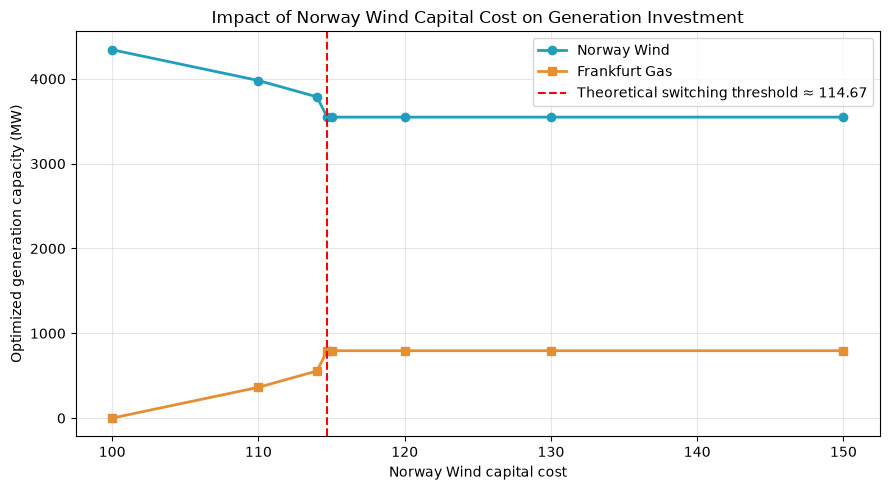

In [27]:
solver_threshold = threshold #pick up the threshold value above for plotting
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    cost_results["Norway Wind capital cost"],
    cost_results["Norway Wind (MW)"],
    marker="o",
    linewidth=2,
    color="#219EBC",
    label="Norway Wind"
)

ax.plot(
    cost_results["Norway Wind capital cost"],
    cost_results["Frankfurt Gas (MW)"],
    marker="s",
    linewidth=2,
    color="#E58F35",
    label="Frankfurt Gas"
)

# Threshold identified from the optimization results
ax.axvline(
    x=solver_threshold,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Theoretical switching threshold ≈ {solver_threshold:.2f}"
)

ax.set_xlabel("Norway Wind capital cost")
ax.set_ylabel("Optimized generation capacity (MW)")
ax.set_title("Impact of Norway Wind Capital Cost on Generation Investment")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("../plots/wind_gas_investment_sensitivity.png", dpi=300)
plt.show()

As shown in the above figure, Norway Wind capacity begins to increase and Frankfurt Gas capacity begin to decreases when the wind capital cost falls below the theoretical threshold of aproximately 114.67.